# Message passing accuracy: clustering

**Internship at CoMuNe Lab** · Riccardo Corte · started on 16 October 2026

Message passing is exact only on tree-like networks. Here we test how its error with respect to
Monte Carlo grows when this assumption is violated, starting from clustering (short loops of length 3).

Structure: 0. setup and tools from notebook 01; 1. random graphs with triangles (Newman 2009).

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from math import comb


rng = np.random.default_rng(0) 


### 0.1 Tools from notebook 01

Copied unchanged from `01_site_percolation_mp_vs_mc.ipynb` (sections 2b, 3 and 4.3). Temporary: to be
moved to a `.py` module and imported, together with the other tests of notebook 01.

In [2]:
def message_passing(G, phi, tol=1e-10, max_iter=10000):
    """Site percolation with message passing (course book v4, sec. 8.2.4, eqs. 8.24-8.26).

    phi: a number (the same for all nodes) or a dict {node: phi of that node}.
    Returns S_MP, s (dict node -> s_i), t (dict (i, j) -> t_{i->j}),
    the number of iterations used and whether the iteration has converged.
    """
    #if nx.number_of_selfloops(G) > 0:
    #    raise ValueError("the network has self-loops: against the assumptions of the model")

    nodi = list(G.nodes())
    phi_n = {n: phi for n in nodi} if np.isscalar(phi) else dict(phi)

    # 2|E| messages: two directions for each link
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]  # the "+" joins the two lists: first the links in the direction given by G.edges(), then reversed

    # for each message i->j, the list of messages it has to read
    # (j->k with k in N_j \ {i}) is computed only once, outside the loop.
    # It is the row i->j of the matrix G from the notes of 8 October.
    # In practice, here we build the 0s and 1s of the matrix G
    da_leggere = {(i, j): [(j, k) for k in G.neighbors(j) if k != i] for (i, j) in messaggi}

    t = {m: 1.0 for m in messaggi}       # start far from t = 0, which is always a solution: starting from 0 we would stay there every time, starting from 1 we do not get stuck in it
    converge = False

    for it in range(1, max_iter + 1):
        # synchronous update: all the new messages from the old ones, t_{n+1} = F(t_n)
        t_new = {}
        for (i, j) in messaggi:
            prod = 1.0                   # empty product = 1: for a leaf j we get t_{i->j} = 0
            for m in da_leggere[(i, j)]:
                prod *= 1.0 - t[m]      # this is the product: no link leads to the GCC
            t_new[(i, j)] = phi_n[j] * (1.0 - prod)          # eq. 8.25: at least one leads to the GCC

        # we stop when no message changes by more than tol
        diff = max((abs(t_new[m] - t[m]) for m in messaggi), default=0.0)
        t = t_new
        if diff < tol:
            converge = True
            break

    # eq. 8.24: one s_i per node (an isolated node has an empty product, so s_i = 0)
    s = {}
    for i in nodi:
        prod = 1.0
        for j in G.neighbors(i):
            prod *= 1.0 - t[(i, j)]
        s[i] = phi_n[i] * (1.0 - prod)

    S_MP = sum(s.values()) / len(nodi)   # eq. 8.26, divided by all the N nodes as in mc_1run
    return S_MP, s, t, it, converge


In [3]:
def mc_1run(G, phi, rng):
    """One run of site percolation. Returns S^MC of that run.

    phi: a number (the same for all nodes) or a dict {node: phi of that node},
    as in message_passing.
    """
    nodi = list(G.nodes)
    N = len(nodi)

    # one phi per node, in the same order as nodi
    phi_n = np.full(N, phi) if np.isscalar(phi) else np.array([phi[n] for n in nodi])

    # one value per node: True (1) if the node stays, with its own probability phi
    presente = rng.random(N) < phi_n
    rimasti = [n for n, c in zip(nodi, presente) if c]

    # limit case: no node left
    if len(rimasti) == 0:
        return 0.0

    # graph with only the nodes left and the links between them
    H = G.subgraph(rimasti)

    # connected groups, sorted from the largest to the smallest
    gruppi = sorted(nx.connected_components(H), key=len, reverse=True)
    lcc = gruppi[0]

    return len(lcc) / N


In [4]:
def curve_mc(G, num_runs, num_phis, rng):
    """Monte Carlo curve on a graph: num_phis values of phi between 0 and 1, num_runs runs for each.
    Returns the values of phi and a matrix with one row per phi and one column per run."""
    phis = np.linspace(0, 1, num_phis)

    results = []

    for i in range(len(phis)):
        intermediate = []
        for k in range(num_runs):
            intermediate.append(mc_1run(G, phis[i], rng))
        results.append(intermediate)

    return phis, np.array(results)


In [5]:
def scarto_quadratico_medio(S_a, S_b):
    """Square root of the mean of the squared differences between two curves computed on the same phi."""
    differenze = np.asarray(S_a) - np.asarray(S_b)
    return np.sqrt(np.mean(differenze ** 2))


Check on `K4` at `φ = 0.6`: `S = 19/45`, as in notebook 01.

In [6]:
K4 = nx.complete_graph(4)
S_MP, s, t, it, ok = message_passing(K4, 0.6)
print("S_MP =", S_MP, " 19/45 =", 19 / 45, " converged:", ok)


S_MP = 0.4222222225227878  19/45 = 0.4222222222222222  converged: True


## 1. Clustering: random graphs with triangles

Model of Newman, *Random graphs with clustering*, PRL 103, 058701 (2009), arXiv:0903.4009: each node
has `s` single links and `t` triangles, total degree `k = s + 2t` (eq. 1); global clustering from eqs. 4-6.
Exactly solvable apart from the triangles, so we can compare Monte Carlo, our message passing and the
exact theory.

### 1.1 Building the networks

Each node gets `s ~ Poisson(ν)` single edges and `t ~ Poisson(μ)` triangles (doubly Poisson case, eq. 13),
so the mean degree is `ν + 2μ`. Stubs are paired at random, corners are grouped three by three (p. 2).

In [7]:
def rete_triangoli(N, nu, mu, rng):
    """Random graph with clustering (Newman 2009, p. 2): s ~ Poisson(nu) single edges and
    t ~ Poisson(mu) triangles per node. Stubs paired at random, corners grouped by three.
    Self-loops and repeated links (footnote 16) are dropped and counted.
    Returns the simple graph, the arrays s and t, and the number of dropped links."""
    s = rng.poisson(nu, N)
    t = rng.poisson(mu, N)
    # total stubs must be a multiple of 2, total corners a multiple of 3 (p. 2)
    while s.sum() % 2 != 0:
        s[rng.integers(N)] += 1
    while t.sum() % 3 != 0:
        t[rng.integers(N)] += 1

    stubs = rng.permutation(np.repeat(np.arange(N), s))
    angoli = rng.permutation(np.repeat(np.arange(N), t))

    links = [(stubs[2 * a], stubs[2 * a + 1]) for a in range(len(stubs) // 2)]
    for a in range(len(angoli) // 3):
        i, j, k = angoli[3 * a: 3 * a + 3]
        links += [(i, j), (j, k), (k, i)]

    G = nx.Graph()
    G.add_nodes_from(range(N))
    G.add_edges_from(links)
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    persi = len(links) - G.number_of_edges()
    return G, s, t, persi


def clustering_teorico(s, t):
    """Global clustering from eqs. 4-6, with the sampled s and t:
    3 N_triangles = sum of t_i (eq. 5), N_triples = sum of k_i (k_i - 1) / 2 (eq. 6), k = s + 2t (eq. 1)."""
    k = s + 2 * t
    return t.sum() / (k * (k - 1) / 2).sum()


Checks at mean degree 3: dropped links (should be few, footnote 16), mean degree, and measured global
clustering (`nx.transitivity`) against eqs. 4-6.

In [8]:
k_medio = 3
mus = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]   # mu = 1.5 means nu = 0: only triangles
N_cl = 1000

reti_cl = {}
righe = []
for mu in mus:
    nu = k_medio - 2 * mu
    g, s, t, persi = rete_triangoli(N_cl, nu, mu, rng)
    reti_cl[mu] = g
    righe.append({"mu": mu, "nu": nu, "links dropped": persi,
                  "mean degree": 2 * g.number_of_edges() / N_cl,
                  "C measured": nx.transitivity(g), "C eqs. 4-6": clustering_teorico(s, t)})
pd.DataFrame(righe).set_index("mu").round(4)


,nu,links dropped,mean degree,C measured,C eqs. 4-6
mu,,,,,
0.00,3.0,7,3.002,0.0047,0.0000
0.25,2.5,4,2.960,0.0555,0.0519
0.50,2.0,5,2.994,0.1028,0.0986
0.75,1.5,4,2.974,0.1421,0.1397
1.00,1.0,1,2.954,0.1832,0.1782
1.25,0.5,3,2.944,0.2257,0.2231
1.50,0.0,12,3.132,0.2435,0.2374


### 1.2 Check against Fig. 2 (right)

Mean degree `ν + 2μ = 2` as in the paper, `N = 10⁴`: size of the largest component (all nodes kept) against
eq. 15, `S = 1 − exp(−[νS + μS(2 − S)])`, solved by iteration from `S = 1`.

In [9]:
def S_eq15(nu, mu, n_iter=10000):
    """Giant component of the doubly Poisson model, eq. 15, by iteration from S = 1."""
    S = 1.0
    for _ in range(n_iter):
        S = 1 - np.exp(-(nu * S + mu * S * (2 - S)))
    return S


righe = []
for mu in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    nu = 2 - 2 * mu
    g, s, t, persi = rete_triangoli(10_000, nu, mu, rng)
    righe.append({"mu": mu, "C measured": nx.transitivity(g),
                  "S measured": mc_1run(g, 1, rng), "S eq. 15": S_eq15(nu, mu)})
pd.DataFrame(righe).set_index("mu").round(4)


,C measured,S measured,S eq. 15
mu,,,
0.0,0.0000,0.7941,0.7968
0.2,0.0929,0.7328,0.7505
0.4,0.1699,0.6926,0.7000
0.6,0.2291,0.6591,0.6480
0.8,0.2887,0.5889,0.5970
1.0,0.3317,0.5393,0.5492


### 1.3 Message passing against Monte Carlo as clustering grows

The networks of section 1.1 (mean degree 3, `N = 1000`; `μ = 0` is a Poisson network like the ER graph of
notebook 01). 21 values of `φ`, 50 Monte Carlo runs per point. Slow: a few minutes.

In [10]:
num_phis_cl = 21
num_runs_cl = 50

S_mc_cl, S_mp_cl, conv_cl = {}, {}, {}
for mu, g in reti_cl.items():
    phis_cl, runs = curve_mc(g, num_runs_cl, num_phis_cl, rng)
    S_mc_cl[mu] = runs.mean(axis=1)
    uscite = [message_passing(g, phi) for phi in phis_cl]
    S_mp_cl[mu] = np.array([u[0] for u in uscite])
    conv_cl[mu] = np.array([u[4] for u in uscite])


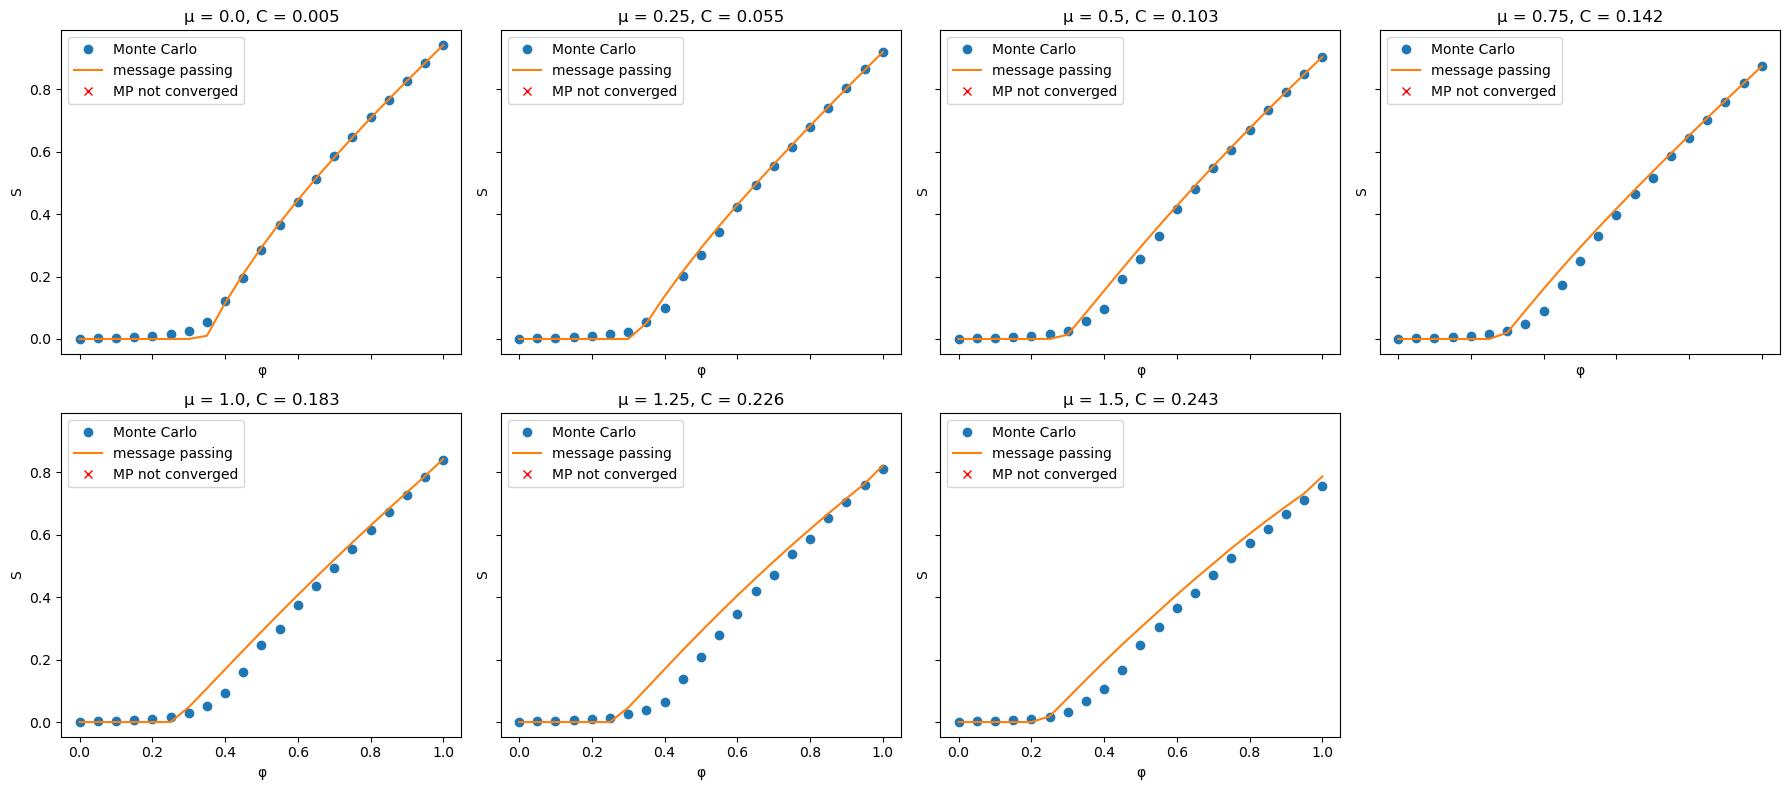

In [11]:
fig, assi = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, (mu, g) in zip(assi.flat, reti_cl.items()):
    ax.plot(phis_cl, S_mc_cl[mu], "o", label="Monte Carlo")
    ax.plot(phis_cl, S_mp_cl[mu], "-", label="message passing")
    ax.plot(phis_cl[~conv_cl[mu]], S_mp_cl[mu][~conv_cl[mu]], "x", color="red", label="MP not converged")
    ax.set_title(f"μ = {mu}, C = {nx.transitivity(g):.3f}")
    ax.set_xlabel("φ")
    ax.set_ylabel("S")
    ax.legend()
assi.flat[-1].axis("off")
plt.tight_layout()
plt.show()


### 1.4 RMS deviation against clustering

Same measure as section 4.3 of notebook 01, one point per network.

           C  RMS deviation
mu                         
0.00  0.0047         0.0129
0.25  0.0555         0.0131
0.50  0.1028         0.0201
0.75  0.1421         0.0258
1.00  0.1832         0.0325
1.25  0.2257         0.0465
1.50  0.2435         0.0418


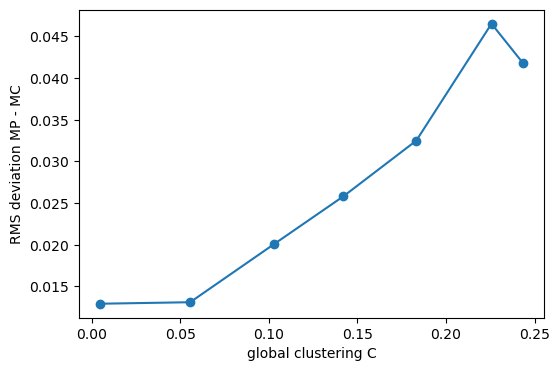

In [12]:
C_cl = [nx.transitivity(g) for g in reti_cl.values()]
rms_cl = [scarto_quadratico_medio(S_mp_cl[mu], S_mc_cl[mu]) for mu in reti_cl]

print(pd.DataFrame({"mu": mus, "C": C_cl, "RMS deviation": rms_cl}).set_index("mu").round(4))

plt.figure(figsize=(6, 4))
plt.plot(C_cl, rms_cl, "o-")
plt.xlabel("global clustering C")
plt.ylabel("RMS deviation MP - MC")
plt.show()


### 1.5 Is the error negligible?

Three measures, each on `R = 10` independent networks per value of `μ` (same parameters as section 1.3):

1. **Error bars**: mean and standard deviation over the `R` networks of the RMS deviation. The value at
   `μ = 0` (no triangles) is the floor due to finite size and Monte Carlo noise.
2. **Maximum deviation** `max_φ |S_MP − S_MC|`: the worst point of the curve, which the RMS averages away.
3. **Threshold**. Message passing: `φ_c = 1/λ_max` of the matrix `G` (notebook 01, section 6).
   Monte Carlo: the `φ` where the susceptibility `χ = (⟨S²⟩ − ⟨S⟩²)/⟨S⟩` is largest.

`matrice_G` and `lambda_max` are copied unchanged from notebook 01, section 6.
Slow: about 100 minutes. With `ESEGUI_RUN = False` (default) the cell reads the results saved in
`errori_clustering.csv` instead of running again.

In [13]:
import scipy.sparse as sp
from scipy.sparse.linalg import eigs


def matrice_G(G):
    """Matrix G of the linearised message passing (notes, Step 5; course book v4, p. 246).
    Rows and columns are the 2|E| messages; G[i->j, j->k] = 1 for every k in N_j other than i.
    Returns G as a sparse CSR matrix and the list of the messages, in the order of the rows."""
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]   # same order as in message_passing
    indice = {m: n for n, m in enumerate(messaggi)}     # message -> its row (and column) number

    righe, colonne = [], []
    for (i, j) in messaggi:
        for k in G.neighbors(j):          # the same loop as da_leggere
            if k != i:
                righe.append(indice[(i, j)])
                colonne.append(indice[(j, k)])

    M = len(messaggi)
    valori = np.ones(len(righe))          # all ones, as floats: eigs works with floating point numbers
    G_mat = sp.csr_matrix((valori, (righe, colonne)), shape=(M, M))
    return G_mat, messaggi


def lambda_max(G_mat):
    """Largest eigenvalue of the sparse matrix G (scipy.sparse.linalg.eigs, ARPACK)."""
    val = eigs(G_mat, k=1, which="LR", return_eigenvectors=False)
    return val[0].real


In [14]:
R = 10                                       # independent networks per value of mu
phis_fini = np.round(np.arange(0.15, 0.605, 0.01), 2)   # finer grid for the Monte Carlo threshold
num_runs_fini = 100

ESEGUI_RUN = False      # True: run again; False: read the results saved in errori_clustering.csv

if ESEGUI_RUN:
    righe = []
    for mu in mus:
        nu = k_medio - 2 * mu
        for r in range(R):
            g, s, t, persi = rete_triangoli(N_cl, nu, mu, rng)

            # measures 1 and 2: the S(phi) curves of section 1.3 on a new network
            phis_cl, runs = curve_mc(g, num_runs_cl, num_phis_cl, rng)
            S_mc = runs.mean(axis=1)
            S_mp = np.array([message_passing(g, phi)[0] for phi in phis_cl])

            # measure 3: Monte Carlo threshold from the peak of the susceptibility (Radicchi 2015, eqs. 2-3)
            runs_fini = np.array([[mc_1run(g, phi, rng) for _ in range(num_runs_fini)] for phi in phis_fini])
            media = runs_fini.mean(axis=1)
            chi = runs_fini.var(axis=1) / np.where(media > 0, media, np.nan)

            righe.append({"mu": mu, "network": r, "C": nx.transitivity(g),
                          "RMS": scarto_quadratico_medio(S_mp, S_mc),
                          "max dev": np.max(np.abs(S_mp - S_mc)),
                          "phi_c MC": phis_fini[np.nanargmax(chi)],
                          "phi_c MP": 1 / lambda_max(matrice_G(g)[0])})

    errori = pd.DataFrame(righe)
    errori.to_csv("errori_clustering.csv", index=False)     # saved, so that the run is not needed again
else:
    errori = pd.read_csv("errori_clustering.csv")


Mean and standard deviation over the `R` networks, one row per `μ`.

In [15]:
sintesi = errori.groupby("mu").agg(["mean", "std"]).drop(columns="network")
sintesi.round(4)


C             RMS         max dev         phi_c MC          \
        mean     std    mean     std    mean     std     mean     std   
mu                                                                      
0.00  0.0035  0.0012  0.0117  0.0013  0.0333  0.0071    0.386  0.0178   
0.25  0.0555  0.0027  0.0139  0.0021  0.0361  0.0066    0.393  0.0177   
0.50  0.1038  0.0050  0.0212  0.0028  0.0536  0.0068    0.398  0.0215   
0.75  0.1459  0.0035  0.0267  0.0017  0.0633  0.0077    0.408  0.0210   
1.00  0.1828  0.0044  0.0326  0.0028  0.0749  0.0084    0.400  0.0216   
1.25  0.2219  0.0056  0.0397  0.0026  0.0845  0.0089    0.399  0.0242   
1.50  0.2525  0.0056  0.0465  0.0036  0.0975  0.0051    0.404  0.0158   

     phi_c MP          
         mean     std  
mu                     
0.00   0.3390  0.0069  
0.25   0.3076  0.0087  
0.50   0.2945  0.0105  
0.75   0.2766  0.0094  
1.00   0.2612  0.0078  
1.25   0.2510  0.0083  
1.50   0.2466  0.0041

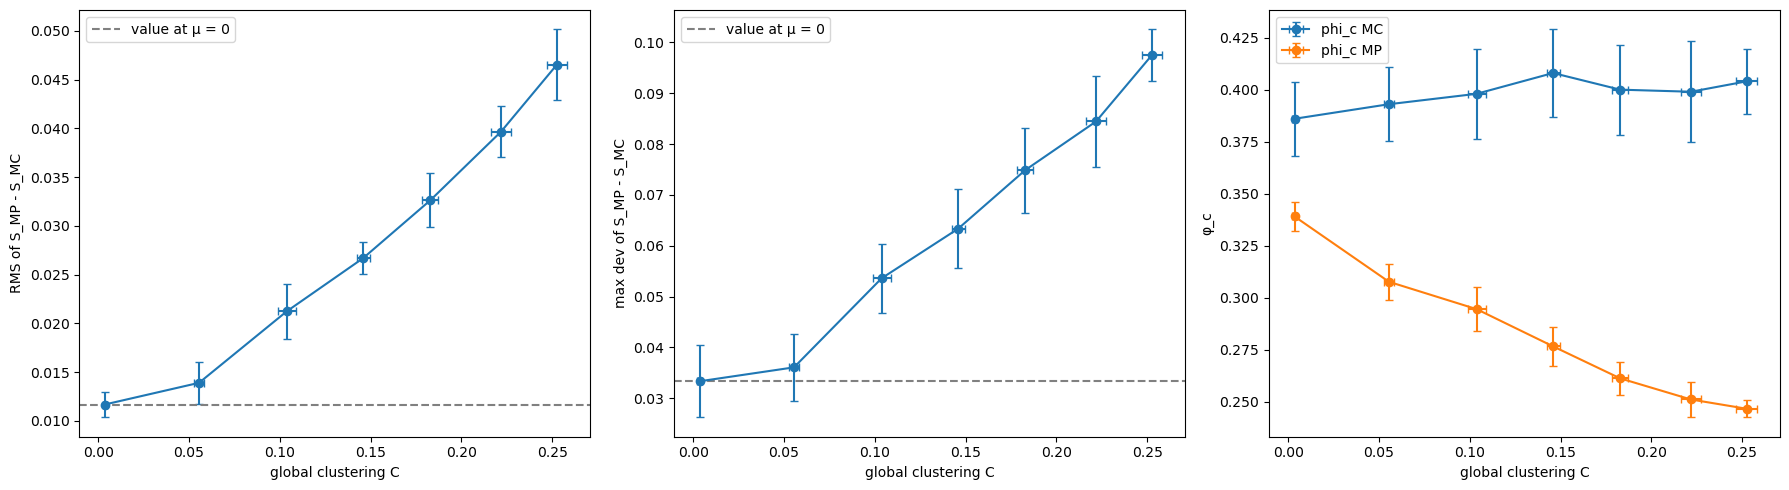

In [16]:
fig, assi = plt.subplots(1, 3, figsize=(18, 5))
x, dx = sintesi[("C", "mean")], sintesi[("C", "std")]

for ax, col in zip(assi[:2], ["RMS", "max dev"]):
    ax.errorbar(x, sintesi[(col, "mean")], xerr=dx, yerr=sintesi[(col, "std")], fmt="o-", capsize=3)
    ax.axhline(sintesi.loc[0.0, (col, "mean")], color="gray", ls="--", label="value at μ = 0")
    ax.set_xlabel("global clustering C")
    ax.set_ylabel(f"{col} of S_MP - S_MC")
    ax.legend()

for col in ["phi_c MC", "phi_c MP"]:
    assi[2].errorbar(x, sintesi[(col, "mean")], xerr=dx, yerr=sintesi[(col, "std")], fmt="o-", capsize=3, label=col)
assi[2].set_xlabel("global clustering C")
assi[2].set_ylabel("φ_c")
assi[2].legend()

plt.tight_layout()
plt.show()


#### Comment on section 1.5

**Result.** As the clustering grows, message passing moves away from Monte Carlo on all three measures, and
the error bars over 10 networks are much smaller than the change. The RMS deviation goes from 0.012 at
`C ≈ 0` to 0.047 at `C ≈ 0.25`, about 4 times larger. The maximum deviation goes from 0.033 to 0.098. With
triangles, message passing **overestimates** `S` at every `φ ≥ 0.5`, and the largest gap is at
`φ ≈ 0.40-0.45`, i.e. right at the true (Monte Carlo) threshold (check on 3 networks per `μ`, outside this
notebook). Without triangles (`μ = 0`) the sign of the gap changes at random from point to point: there it is
only finite size and Monte Carlo noise, and these values are the floor to compare with.

**Away from the threshold the error is small, close to it the error is large.** On most of the `S(φ)` curve
the two methods differ by a few hundredths. The real problem is the position of the threshold. Monte Carlo
gives `φ_c ≈ 0.38-0.41` for every `C`, while message passing goes from 0.339 at `C ≈ 0` to 0.247 at
`C ≈ 0.25`. The gap grows from 12% of the true value (the floor, due to finite size) to almost 39%. So message passing
predicts that the network collapses only after 75% of the nodes are removed, while it really collapses after 60%: it
believes the network is more robust than it is. Close to the threshold the method is not reliable, and we
have to take this into account when we apply it to real networks with high clustering.

**Why.** In eq. 8.25 the product treats the messages coming from the different neighbours as independent. In
a triangle `i-j-k` the neighbours `j` and `k` are also linked to each other, so their messages to `i` are
correlated: message passing counts the same route to the giant component twice and overestimates the
connectivity.

**Threshold.** Raising `μ` at fixed mean degree changes two things at the same time.
1. The degrees become more spread out, `Var(k) = 3 + 2μ`. More hubs make the network more robust, so the
   threshold goes down. Message passing sees only this effect: its `φ_c` follows Molloy-Reed,
   `⟨k⟩/(⟨k²⟩ − ⟨k⟩) = 3/(9 + 2μ)` (course book v4, pp. 238-239), i.e. 0.333, 0.300, 0.273, 0.250 for
   `μ = 0, 0.5, 1, 1.5`, against 0.339, 0.295, 0.261, 0.247 measured.
2. The triangles make the network more fragile: one link out of three in a triangle joins two nodes that are
   already connected, so with the same number of links fewer new nodes are reached (Newman 2009, p. 3).
   This pushes the threshold up.

Monte Carlo sees both effects and finds a threshold that stays about constant. Our reading is that the two
effects roughly cancel; this is a hypothesis, which the exact site theory on these networks can check.

**Limits.** One mean degree (3), one size (`N = 1000`), and Newman's networks, where the triangles are isolated
and there are almost no other short loops. In real networks triangles overlap and longer loops are present,
so the same `C` may give a different error: `C` alone is not enough to judge the reliability of message
passing on a given network.

### 1.6 Relative error on the threshold

The RMS deviation measures the error on the whole curve `S(φ)`; for screening what matters most is the position
of the threshold. Relative error of the message passing threshold with respect to the Monte Carlo one,
`(φ_c MP − φ_c MC) / φ_c MC`, in percent, mean and standard deviation over the `R = 10` networks per `μ`.
Computed from the table of section 1.5 (`errori`, also saved in `errori_clustering.csv`), no new runs.

In [17]:
errori["err phi_c %"] = 100 * (errori["phi_c MP"] - errori["phi_c MC"]) / errori["phi_c MC"]
errori.groupby("mu")[["C", "RMS", "err phi_c %"]].agg(["mean", "std"]).round(3)


C           RMS        err phi_c %       
       mean    std   mean    std        mean    std
mu                                                 
0.00  0.003  0.001  0.012  0.001     -12.042  3.461
0.25  0.055  0.003  0.014  0.002     -21.649  2.484
0.50  0.104  0.005  0.021  0.003     -25.881  3.616
0.75  0.146  0.004  0.027  0.002     -32.124  2.625
1.00  0.183  0.004  0.033  0.003     -34.610  2.198
1.25  0.222  0.006  0.040  0.003     -36.901  4.087
1.50  0.253  0.006  0.047  0.004     -38.884  2.637

**Comment.** On the curve the error stays small (RMS at most 0.05 on a scale from 0 to 1), on the threshold it
does not: message passing puts `φ_c` 39% below Monte Carlo at `C ≈ 0.25`. Already at `μ = 0`, with no
triangles, the error is −12%, while there message passing is close to the exact value (0.339 against
`1/3` from Molloy-Reed). So the floor comes mostly from the Monte Carlo estimate, not from message passing:
with `N = 1000` the peak of the susceptibility falls above the true threshold (checked in section 1.7). The effect of the triangles is the growth from −12% to
−39%, about ten times the spread over the networks (2-4 points).

### 1.7 Threshold error as the size of the network grows

Check of the floor of section 1.6: if the −12% at `μ = 0` comes from the Monte Carlo estimate at `N = 1000`,
it must shrink as `N` grows, while the part due to the triangles must stay. Same threshold measures as in
section 1.5 (peak of `χ` for Monte Carlo, `1/λ_max` for message passing), for `N = 1000, 3000, 10000` and
`μ = 0, 0.75, 1.5`, on `R_N = 5` networks per case. The `S(φ)` curves of message passing are not needed here.
The grid of `φ` is restricted to 0.25-0.50 around the Monte Carlo thresholds of section 1.5 (0.39-0.41); if
the peak falls on an edge of the grid, the cell says so and the grid has to be widened.

Needs only sections 0, 1.1 (`rete_triangoli`, `k_medio`) and the cell of section 1.5 with `matrice_G` and
`lambda_max`: the slow cells of 1.3 and 1.5 can be skipped. Slow: about 30-40 minutes, most of it for
`N = 10000`. With `ESEGUI_RUN_N = False` (default) the cell reads `soglie_N.csv` instead of running again.

In [18]:
dimensioni_cl = [1000, 3000, 10000]
mus_N = [0.0, 0.75, 1.5]
R_N = 5                                                     # networks per (N, mu)
phis_soglia = np.round(np.arange(0.25, 0.505, 0.01), 2)    # grid around the Monte Carlo thresholds
num_runs_soglia = 100

ESEGUI_RUN_N = False      # True: run again; False: read the results saved in soglie_N.csv

if ESEGUI_RUN_N:
    righe = []
    for N in dimensioni_cl:
        for mu in mus_N:
            nu = k_medio - 2 * mu
            for r in range(R_N):
                g, s, t, persi = rete_triangoli(N, nu, mu, rng)

                # Monte Carlo threshold: peak of the susceptibility, as in section 1.5
                runs = np.array([[mc_1run(g, phi, rng) for _ in range(num_runs_soglia)] for phi in phis_soglia])
                media = runs.mean(axis=1)
                chi = runs.var(axis=1) / np.where(media > 0, media, np.nan)
                picco = np.nanargmax(chi)
                if picco in (0, len(phis_soglia) - 1):
                    print(f"N = {N}, mu = {mu}, network {r}: peak on the edge of the grid (phi = {phis_soglia[picco]})")

                righe.append({"N": N, "mu": mu, "network": r, "C": nx.transitivity(g),
                              "phi_c MC": phis_soglia[picco],
                              "phi_c MP": 1 / lambda_max(matrice_G(g)[0])})

    soglie_N = pd.DataFrame(righe)
    soglie_N["err phi_c %"] = 100 * (soglie_N["phi_c MP"] - soglie_N["phi_c MC"]) / soglie_N["phi_c MC"]
    soglie_N.to_csv("soglie_N.csv", index=False)     # saved, so that the run is not needed again
else:
    soglie_N = pd.read_csv("soglie_N.csv")


In [19]:
sintesi_N = soglie_N.groupby(["N", "mu"])[["C", "phi_c MC", "phi_c MP", "err phi_c %"]].agg(["mean", "std"])
sintesi_N.round(3)


C        phi_c MC        phi_c MP        err phi_c %       
             mean    std     mean    std     mean    std        mean    std
N     mu                                                                   
1000  0.00  0.003  0.002    0.412  0.004    0.335  0.005     -18.586  1.400
      0.75  0.148  0.004    0.408  0.019    0.276  0.007     -32.154  3.023
      1.50  0.258  0.006    0.414  0.040    0.248  0.006     -39.790  4.120
3000  0.00  0.001  0.000    0.360  0.010    0.327  0.002      -9.172  2.963
      0.75  0.144  0.002    0.380  0.007    0.277  0.004     -27.136  1.037
      1.50  0.251  0.002    0.378  0.011    0.241  0.002     -36.235  2.083
10000 0.00  0.000  0.000    0.362  0.004    0.334  0.003      -7.680  1.364
      0.75  0.143  0.001    0.364  0.017    0.273  0.004     -24.828  2.846
      1.50  0.250  0.001    0.374  0.018    0.242  0.001     -35.183  2.936

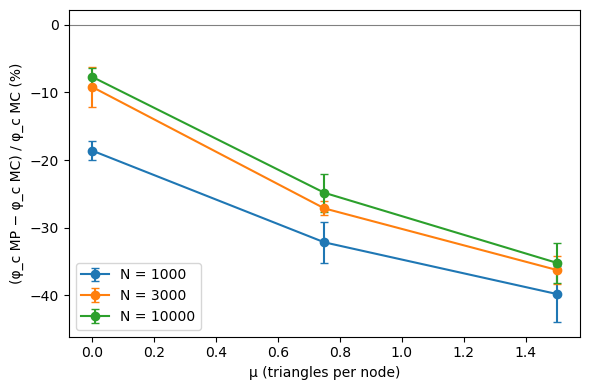

In [20]:
# relative threshold error against mu, one colour per N
fig, ax = plt.subplots(figsize=(6, 4))
for N in dimensioni_cl:
    righe_N = sintesi_N.loc[N]
    ax.errorbar(righe_N.index, righe_N[("err phi_c %", "mean")], yerr=righe_N[("err phi_c %", "std")],
                fmt="o-", capsize=3, label=f"N = {N}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("μ (triangles per node)")
ax.set_ylabel("(φ_c MP − φ_c MC) / φ_c MC (%)")
ax.legend()
plt.tight_layout()
plt.show()


#### Comment on section 1.7

As `N` grows the floor at `μ = 0` shrinks, from −19% at `N = 1000` to −9% at `N = 3000` and −8% at
`N = 10000`, but it does not disappear. Message passing gives `φ_c ≈ 0.33` (the Molloy-Reed value `1/3`) at
every `N`, so all the change is in the Monte Carlo estimate: the peak of `χ` moves from 0.41 to 0.36 and then
stops. At `N = 1000` the floor is −19% here and −12% in section 1.6: same estimate on different networks, and at
this size the Monte Carlo threshold changes by about 0.02 from network to network (section 1.5).

The floor is not due to Newman's networks: on Erdős-Rényi graphs with the same mean degree the same estimate
gives the same thresholds (check outside this notebook, 5 networks: 0.400 against 0.392 at `N = 1000`, 0.370
against 0.368 at `N = 3000`). It comes from estimating the threshold from the peak of `χ` on a finite network.
With a step of 0.01 in `φ` (3% of the threshold) and 100 runs per point, the last few percent cannot be
resolved here (hypothesis).

The part due to the triangles does not shrink with `N`: at `N = 10000` the error is −25% at `μ = 0.75` and
−35% at `μ = 1.5`, 17 and 27 points beyond the floor. This is the real error of message passing on clustered
networks; the floor of about 8% is a limit of how we measure the Monte Carlo threshold.